# Kron reduction: what the 13 types missing from the 72-type list do

**Question.** The earlier 72-type parameterisation (`data/types_72.csv`, the row set of the
archived `schur_decomp/outputs/moved_csv/matrices/archive/w_ij_gaa.csv`) is an exact subset of
the current 85-type operator. The 13 types it lacks are cells that receive from and project to
the other 72. A 72-type model *truncates* them. Kron reduction *eliminates* them: it folds every
path that passes through them back into an effective 72×72 operator. The gap between the two is
the cost of leaving them out.

The 85 → 72 case is a calibration experiment for a question we cannot answer directly: the
85-type operator is itself a truncation of the 122-type Hippocampome circuit (37 types lack the
parameters needed for $m_{ij}$). Here the "missing" types have known parameters, so every
estimate can be checked against the truth.

**Model.** As in `jacobian_analysis`: $\tau\dot x = -x + Wx + u$, $J = -I + W$,
$W = M[\text{post},\text{pre}]$ normalised once to $\rho(W)=0.95$ on the full 85 types.
Partition kept $K$ (72) and eliminated $R$ (13).

| Operator | Definition | Meaning |
|---|---|---|
| truncation | $W_{KK}$ | what a 72-type model is |
| static Kron | $W_{KK} + W_{KR}(I-W_{RR})^{-1}W_{RK}$ | exact at steady state |
| dynamic Kron | $W_{KK} + W_{KR}((1+s)I-W_{RR})^{-1}W_{RK}$ | exact at every frequency $s$ |

The correction is $W_{KR}(I + W_{RR} + W_{RR}^2 + \dots)W_{RK}$: the sum over every path that leaves
$K$, passes through the hidden types, and comes back. It is the same Schur complement as the
inhibitory $M_{\text{eff},E}$ in `inhib_modulation`, with a different choice of what to hide.

**Conventions.** The matrix on disk is `[pre, post]`. `jacobian_core.load_jacobian_data`
transposes it and checks the result with the Dale's-law sign test. Blocks are named in the
arrow sense: `E_to_I` means an E source and an I receiver. All magnitudes are conditional on
$\rho = 0.95$, so read them comparatively.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import expm
from scipy.stats import spearmanr

import kron_core as kc

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})
FIG = kc.HERE / "outputs"
FIG.mkdir(exist_ok=True)

P = kc.load_partition()
K, R, W, ei = P.keep, P.elim, P.W, P.ei
print("orientation check:", P.orientation_check)
print(f"kept {len(K)}  eliminated {len(R)}  (E {np.sum(ei[R]=='e')}, I {np.sum(ei[R]=='i')})")

orientation check: {'E_to_I_positive': 1.0, 'I_to_E_negative': 1.0, 'n_excitatory': 32.0, 'n_inhibitory': 53.0}
kept 72  eliminated 13  (E 4, I 9)


## 1. The 13 types

`in` counts and strengths are inputs *to* the type from the 72 (row of $W$). `out` are its outputs
*onto* the 72 (column). A type contributes to the Kron correction only if it has both. A
pure source or pure sink of the kept set contributes exactly zero.

In [2]:
hidden = pd.DataFrame({
    "neuron_type": P.labels[R],
    "ei": ei[R],
    "region": [kc.region_of(x) for x in P.labels[R]],
    "q_i": P.q[R],
    "kappa_j": P.kappa[R],
    "n_in_from_72": [(W[r, K] != 0).sum() for r in R],
    "n_out_to_72": [(W[K, r] != 0).sum() for r in R],
    "self_weight": W[R, R],
})
print("edges among the 13:", int((W[np.ix_(R, R)] != 0).sum() - (np.diag(W[np.ix_(R, R)]) != 0).sum()),
      " rho(W_RR) =", round(float(np.max(np.abs(np.linalg.eigvals(W[np.ix_(R, R)])))), 4))
kc.save(hidden, "hidden_13_types")
hidden

edges among the 13: 38  rho(W_RR) = 0.1667


,neuron_type,ei,region,q_i,kappa_j,n_in_from_72,n_out_to_72,self_weight
0,CA1 Back Projection,i,CA1,793,0.1938,14,44,-0.007116
1,CA1 Bistratified,i,CA1,804,0.08922,22,23,-0.005266
2,CA1 O LM,i,CA1,521,0.04818,14,13,0
3,CA1 Quadrilaminar,i,CA1,9,0.07486,24,24,-4.418e-05
4,CA2 Pyramidal,e,CA2,7772,0.01469,8,45,0.0784
5,CA3 Basket CCK+,i,CA3,167,0.08623,14,5,-0.04674
6,CA3 Horizontal Axo Axonic,i,CA3,1342,0.07827,5,2,0
7,CA3 Mossy Fiber Associated,i,CA3,182,0.1085,11,19,-0.00151
8,CA3 O LM,i,CA3,868,0.178,5,9,-0.005915
9,DG Hilar Ectopic Granule,e,DG,37,0.02539,21,17,3.339e-05


## 2. Exactness check

Static Kron reduction must reproduce the 72×72 block of the full steady-state response
$(I-W)^{-1}$ to machine precision. Truncation has no such guarantee.

In [3]:
W_trunc = kc.truncate(W, K)
D = kc.kron_correction(W, K, R)
W_kron = W_trunc + D

G_full = kc.transfer(W)
G_ref = G_full[np.ix_(K, K)]
print(f"steady-state error, static Kron : {kc.rel_err(kc.transfer(W_kron), G_ref):.2e}")
print(f"steady-state error, truncation  : {kc.rel_err(kc.transfer(W_trunc), G_ref):.3f}")
for s in (0.3j, 1.0j, 2.0 + 0.5j):
    Gs = kc.transfer(W, s)[np.ix_(K, K)]
    print(f"dynamic Kron at s={s}: {kc.rel_err(kc.transfer(kc.kron_reduce(W, K, R, s), s), Gs):.2e}")

# The single drive used as the GSN target elsewhere in the repo
g = int(np.flatnonzero(P.labels[K] == "DG Granule")[0])
resp_full, resp_trunc = G_ref[:, g], kc.transfer(W_trunc)[:, g]
print(f"\nDG Granule drive: truncation error {kc.rel_err(resp_trunc, resp_full):.3f}, "
      f"Spearman {spearmanr(resp_full, resp_trunc).statistic:.3f}")

steady-state error, static Kron : 6.67e-15
steady-state error, truncation  : 0.720
dynamic Kron at s=0.3j: 3.52e-15
dynamic Kron at s=1j: 4.89e-16
dynamic Kron at s=(2+0.5j): 3.99e-16

DG Granule drive: truncation error 0.161, Spearman 0.977


## 3. Operator comparison

`full85` is the reference. `trunc72` and `kron72` keep the full-85 scale; the `_renorm`
rows rescale to $\rho=0.95$ the way an independent 72-type analysis would, which removes the
stability shift and keeps only the change in shape.

In [4]:
pos = P.order_position
rows = [
    kc.operator_summary(W, ei, pos, "full85"),
    kc.operator_summary(W_trunc, ei[K], pos[K], "trunc72"),
    kc.operator_summary(W_kron, ei[K], pos[K], "kron72"),
    kc.operator_summary(kc.renormalise(W_trunc), ei[K], pos[K], "trunc72_renorm"),
    kc.operator_summary(kc.renormalise(W_kron), ei[K], pos[K], "kron72_renorm"),
]
summary = pd.DataFrame(rows).set_index("operator")
kc.save(summary, "operator_comparison", index=True)
cols = ["n_edges", "rho_W", "stability_margin", "numerical_abscissa_J", "henrici_relative",
        "peak_amplification", "time_of_peak", "E_to_I_over_I_to_E", "forward_weight_fraction",
        "dale_wrong_sign_entries", "dale_wrong_sign_weight_share", "dale_mixed_sign_columns"]
summary[cols]

,n_edges,rho_W,stability_margin,numerical_abscissa_J,henrici_relative,peak_amplification,time_of_peak,E_to_I_over_I_to_E,forward_weight_fraction,dale_wrong_sign_entries,dale_wrong_sign_weight_share,dale_mixed_sign_columns
operator,,,,,,,,,,,,
full85,1641,0.95,0.05,29.58,0.993,27.13,1.25,911.8,0.9952,0,0,0
trunc72,1151,0.9791,0.02085,29.06,0.9936,24.99,1.15,2308,0.9959,0,0,0
kron72,2933,0.9512,0.04878,31.81,0.9943,28.39,1.2,2497,0.9962,940,0.0003444,57
trunc72_renorm,1151,0.95,0.05,28.16,0.9933,24.14,1.15,2308,0.9959,0,0,0
kron72_renorm,2933,0.95,0.05,31.77,0.9943,28.35,1.2,2497,0.9962,940,0.0003444,57


**Two checks on the table.** (a) Why the E→I / I→E ratio moves: I→E weight is concentrated in
a few interneuron types, and some of them are among the 13. (b) Whether the repository's
orientation oracle `assert_post_pre` still accepts a reduced operator. It uses the *count*
purity of signs in the E→I and I→E blocks.

In [5]:
E_, I_ = ei == "e", ei == "i"
hid = np.zeros(P.n, bool); hid[R] = True
ie = np.abs(W[np.ix_(E_, I_)])
print(f"share of full-85 I->E |weight| sent by the 9 hidden interneurons: {ie[:, hid[I_]].sum() / ie.sum():.3f}")

floor = 1e-12 * np.abs(W).max()
for name, M in [("trunc72", W_trunc), ("kron72", W_kron)]:
    for orient, A in [("as is", M), ("transposed", M.T)]:
        try:
            res = kc.jc.assert_post_pre(np.where(np.abs(A) > floor, A, 0.0), list(ei[K]))
            print(f"{name:8s} {orient:10s} passes  {res['E_to_I_positive']:.3f} / {res['I_to_E_negative']:.3f}")
        except ValueError as exc:
            msg = str(exc)
            print(f"{name:8s} {orient:10s} RAISES  {msg[msg.index(':') + 2:msg.index('. ')]}")

share of full-85 I->E |weight| sent by the 9 hidden interneurons: 0.312
trunc72  as is      passes  1.000 / 1.000
trunc72  transposed RAISES  E_to_I_positive=0.000, I_to_E_negative=0.000
kron72   as is      RAISES  E_to_I_positive=0.575, I_to_E_negative=0.782
kron72   transposed RAISES  E_to_I_positive=0.218, I_to_E_negative=0.425


## 4. What the correction adds

Block decomposition of $\Delta = W_{KR}(I-W_{RR})^{-1}W_{RK}$, in the arrow sense, against the
same block of $W_{KK}$. "Fill-in" counts entries that are zero in $W_{KK}$ and non-zero in $\Delta$.
These are effective connections that exist only through a hidden type.

In [6]:
eK = ei[K]
floor = 1e-12 * np.abs(W).max()
brows = []
for src in "ei":
    for tgt in "ei":
        blk = D[np.ix_(eK == tgt, eK == src)]
        base = W_trunc[np.ix_(eK == tgt, eK == src)]
        sign = 1 if src == "e" else -1
        nz = np.abs(blk) > floor
        brows.append({
            "block": f"{src.upper()}_to_{tgt.upper()}",
            "fro_W_KK": np.linalg.norm(base),
            "fro_correction": np.linalg.norm(blk),
            "correction_rel": np.linalg.norm(blk) / np.linalg.norm(base),
            "nonzero_correction": int(nz.sum()),
            "fill_in": int((nz & (base == 0)).sum()),
            "dale_consistent_share": float(np.abs(blk[(blk * sign) > 0]).sum() / np.abs(blk).sum()),
        })
blocks = pd.DataFrame(brows)
kc.save(blocks, "correction_by_block")
print(f"||Delta||_F / ||W_KK||_F = {np.linalg.norm(D)/np.linalg.norm(W_trunc):.4f}")
blocks

||Delta||_F / ||W_KK||_F = 0.0868


,block,fro_W_KK,fro_correction,correction_rel,nonzero_correction,fill_in,dale_consistent_share
0,E_to_E,4.641,0.4195,0.09038,437,196,0.5096
1,E_to_I,74.46,6.464,0.08681,949,747,0.9917
2,I_to_E,0.03226,0.00221,0.0685,210,132,0.3292
3,I_to_I,0.2767,0.02502,0.09042,1193,708,0.8121


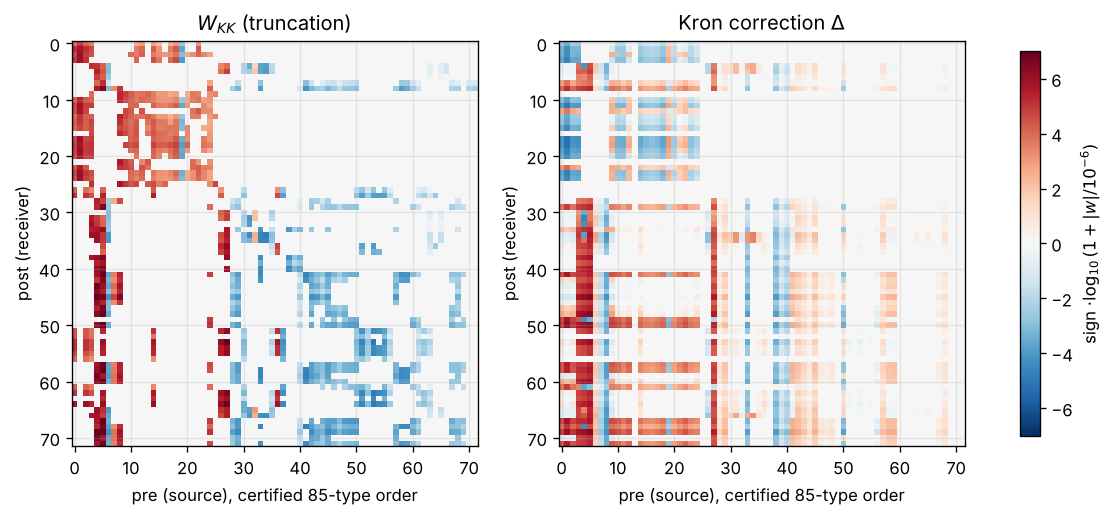

In [7]:
order = np.argsort(pos[K])
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, M, title in [(axes[0], W_trunc, r"$W_{KK}$ (truncation)"), (axes[1], D, r"Kron correction $\Delta$")]:
    A = M[np.ix_(order, order)]
    im = ax.imshow(np.sign(A) * np.log10(1 + np.abs(A) / 1e-6), cmap="RdBu_r", vmin=-7, vmax=7)
    ax.set_title(title)
    ax.set_xlabel("pre (source), certified 85-type order")
    ax.set_ylabel("post (receiver)")
fig.colorbar(im, ax=axes, shrink=0.8, label=r"sign $\cdot \log_{10}(1+|w|/10^{-6})$")
fig.savefig(FIG / "correction_heatmap.png", bbox_inches="tight")
plt.show()

## 5. Which of the 13 matter: attribution and a first-order screen

Leave-one-out from the full 85 for each hidden type. `exact_restore_shift` is
$\rho(W) - \rho(W_{-r})$, the change in the dominant eigenvalue from putting type $r$ back.
`first_order_restore_shift` predicts it from the rank-1 Kron correction alone:

$$\delta\lambda \approx \frac{u^\top \Delta_r v}{u^\top v}, \qquad \Delta_r = \frac{W_{K r} W_{r K}}{1 - W_{rr}}$$

with $u, v$ the left and right dominant eigenvectors of the truncated operator. It needs only
the type's in- and out-weights, so it can be run on *imputed* weights for types that have no
parameters.

In [8]:
single = kc.single_node_table(P)
kc.save(single, "single_type_attribution")
print("corr(exact, first-order) =", round(single[["exact_restore_shift", "first_order_restore_shift"]].corr().iloc[0, 1], 6))
print("Spearman(|correction| norm, |exact shift|) =",
      round(spearmanr(single.kron_correction_fro, single.exact_restore_shift.abs()).statistic, 3))

lam, v, u = kc.dominant_pair(W)
cond = np.linalg.norm(u) * np.linalg.norm(v) / abs(u @ v)
top = np.argsort(-np.abs(v))[:6]
print(f"\nfull-85 dominant eigenvalue {lam.real:.3f}, eigenvalue condition number {cond:.1f}")
print(pd.DataFrame({"type": P.labels[top], "ei": ei[top],
                    "|right loading|": np.abs(v[top]) / np.linalg.norm(v),
                    "|left loading|": np.abs(u[top]) / np.linalg.norm(u)}).to_string(index=False))
single[["neuron_type", "ei", "n_in", "n_out", "in_strength", "out_strength", "kron_correction_rel",
        "rho_if_deleted", "exact_restore_shift", "first_order_restore_shift"]]

corr(exact, first-order) = 0.999987
Spearman(|correction| norm, |exact shift|) = 0.901

full-85 dominant eigenvalue 0.950, eigenvalue condition number 19.9
                                       type ei  |right loading|  |left loading|
MEC LIII Superficial Multipolar Interneuron  i           0.6704        0.002261
                             CA1 Trilaminar  i           0.4928       1.045e-05
        CA1 Perforant Path Associated QuadD  i           0.2874       3.751e-08
              CA1 Perforant Path Associated  i           0.2274       9.326e-06
                              DG Axo Axonic  i           0.1941       1.176e-06
                                  DG AIPRIM  i           0.1377       1.792e-05


,neuron_type,ei,n_in,n_out,in_strength,out_strength,kron_correction_rel,rho_if_deleted,exact_restore_shift,first_order_restore_shift
0,MEC LIII Superficial Multipolar Interneuron,i,16,16,21.01,0.0656,0.004033,0.983,-0.03297,-0.03171
1,CA1 Back Projection,i,18,52,7.695,0.4111,0.006581,0.9502,-0.0002102,-0.000209
2,CA3 Basket CCK+,i,19,5,0.8196,0.3253,0.0009202,0.9501,-0.0001379,-0.0001317
3,CA1 Bistratified,i,26,26,8.091,0.178,0.004636,0.95,-9.541e-06,-9.064e-06
4,CA3 O LM,i,7,12,0.8091,0.08703,0.0002715,0.95,-6.319e-06,-6.02e-06
5,SUB CA1 Projecting Pyramidal,e,12,21,0.3687,0.3157,0.0003124,0.95,-5.504e-06,-5.234e-06
6,CA3 Mossy Fiber Associated,i,15,21,1.254,0.02537,7.13e-05,0.95,-2.491e-06,-2.367e-06
7,CA1 O LM,i,18,14,2.23,0.02301,0.0002066,0.95,-8.238e-07,-7.827e-07
8,CA3 Horizontal Axo Axonic,i,8,2,0.3893,0.0003489,9.443e-07,0.95,-4.349e-07,-4.132e-07
9,CA1 Quadrilaminar,i,30,27,6.212,0.001258,2.68e-05,0.95,-6.89e-08,-6.546e-08


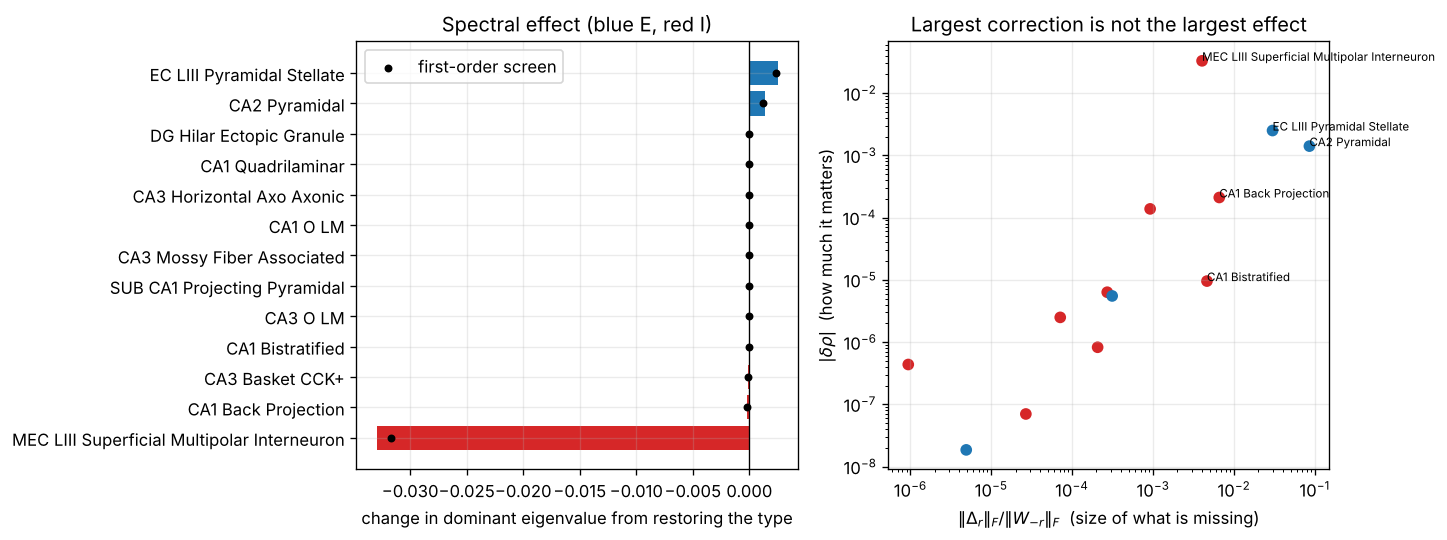

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
s = single.sort_values("exact_restore_shift")
colors = ["tab:blue" if c == "e" else "tab:red" for c in s.ei]
axes[0].barh(s.neuron_type, s.exact_restore_shift, color=colors)
axes[0].scatter(s.first_order_restore_shift, s.neuron_type, color="k", s=14, zorder=3, label="first-order screen")
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel(r"change in dominant eigenvalue from restoring the type")
axes[0].set_title("Spectral effect (blue E, red I)")
axes[0].legend(loc="upper left")
axes[1].scatter(single.kron_correction_rel, single.exact_restore_shift.abs() + 1e-9,
                c=["tab:blue" if c == "e" else "tab:red" for c in single.ei])
for _, r in single.iterrows():
    if r.kron_correction_rel > 1e-3 or abs(r.exact_restore_shift) > 1e-3:
        axes[1].annotate(r.neuron_type, (r.kron_correction_rel, abs(r.exact_restore_shift) + 1e-9), fontsize=7)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel(r"$\|\Delta_r\|_F / \|W_{-r}\|_F$  (size of what is missing)")
axes[1].set_ylabel(r"$|\delta\rho|$  (how much it matters)")
axes[1].set_title("Largest correction is not the largest effect")
fig.tight_layout()
fig.savefig(FIG / "single_type_attribution.png", bbox_inches="tight")
plt.show()

## 6. Dynamics: static Kron is a steady-state method

The exact 72-type transient is the $KK$ block of the full propagator, $[e^{Jt}]_{KK}$
(dynamic Kron reproduces it exactly). Compare the worst-case envelope $\|\cdot\|_2$ and the
relative error of truncation and static Kron. In frequency, compare transfer functions
$G(i\omega)$.

exact_KK     peak  26.58 at t = 1.2 tau
truncation   peak  24.97 at t = 1.1 tau
static_kron  peak  28.39 at t = 1.2 tau
static Kron beats truncation for omega < 1.04 / tau


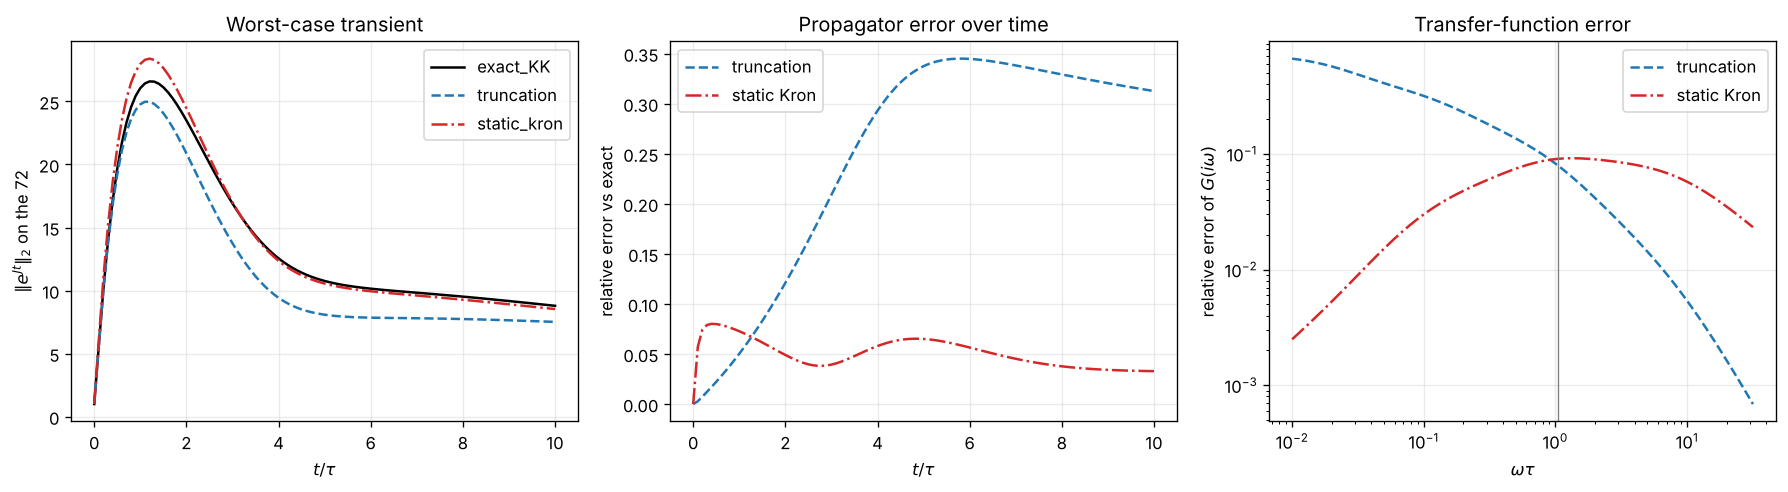

In [10]:
J = W - np.eye(P.n)
I72 = np.eye(len(K))
rows = []
for t in kc.TIMES:
    E = expm(J * t)[np.ix_(K, K)]
    Et = expm((W_trunc - I72) * t)
    Ek = expm((W_kron - I72) * t)
    rows.append({"time": t, "exact_KK": np.linalg.norm(E, 2), "truncation": np.linalg.norm(Et, 2),
                 "static_kron": np.linalg.norm(Ek, 2),
                 "err_truncation": kc.rel_err(Et, E) if t > 0 else 0.0,
                 "err_static_kron": kc.rel_err(Ek, E) if t > 0 else 0.0})
dyn = pd.DataFrame(rows)
kc.save(dyn, "transient_envelopes")

omegas = np.logspace(-2, 1.5, 60)
frows = []
for w_ in omegas:
    Gs = kc.transfer(W, 1j * w_)[np.ix_(K, K)]
    frows.append({"omega": w_,
                  "err_truncation": kc.rel_err(kc.transfer(W_trunc, 1j * w_), Gs),
                  "err_static_kron": kc.rel_err(kc.transfer(W_kron, 1j * w_), Gs)})
freq = pd.DataFrame(frows)
kc.save(freq, "frequency_errors")
cross = freq.omega[np.argmax((freq.err_static_kron > freq.err_truncation).to_numpy())]

pk = {c: (dyn[c].max(), dyn.time[dyn[c].idxmax()]) for c in ["exact_KK", "truncation", "static_kron"]}
for c, (p, t) in pk.items():
    print(f"{c:12s} peak {p:6.2f} at t = {t:.1f} tau")
print(f"static Kron beats truncation for omega < {cross:.2f} / tau")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for c, st in [("exact_KK", "k-"), ("truncation", "C0--"), ("static_kron", "C3-.")]:
    axes[0].plot(dyn.time, dyn[c], st, label=c)
axes[0].set_xlabel(r"$t/\tau$"); axes[0].set_ylabel(r"$\|e^{Jt}\|_2$ on the 72"); axes[0].legend()
axes[0].set_title("Worst-case transient")
axes[1].plot(dyn.time, dyn.err_truncation, "C0--", label="truncation")
axes[1].plot(dyn.time, dyn.err_static_kron, "C3-.", label="static Kron")
axes[1].set_xlabel(r"$t/\tau$"); axes[1].set_ylabel("relative error vs exact"); axes[1].legend()
axes[1].set_title("Propagator error over time")
axes[2].loglog(freq.omega, freq.err_truncation, "C0--", label="truncation")
axes[2].loglog(freq.omega, freq.err_static_kron, "C3-.", label="static Kron")
axes[2].axvline(cross, color="gray", lw=0.8)
axes[2].set_xlabel(r"$\omega\tau$"); axes[2].set_ylabel(r"relative error of $G(i\omega)$"); axes[2].legend()
axes[2].set_title("Transfer-function error")
fig.tight_layout()
fig.savefig(FIG / "dynamics_truncation_vs_kron.png", bbox_inches="tight")
plt.show()

## 7. Dependence on the operating point

The correction is a resolvent, so its size depends on the gain. Sweep the full-85 normalisation
and repeat the truncation-vs-Kron comparison at each gain. 0.85 is the convention for the
inhibitory analyses and 0.95 for the rest.

In [11]:
grows = []
for gain in [0.5, 0.7, 0.85, 0.9, 0.95, 0.98, 0.99]:
    Pg = kc.load_partition(gain)
    Gg = kc.transfer(Pg.W)[np.ix_(K, K)]
    Wt = kc.truncate(Pg.W, K)
    Dg = kc.kron_correction(Pg.W, K, R)
    rt = float(np.max(np.abs(np.linalg.eigvals(Wt))))
    grows.append({"rho_full": gain,
                  "rho_truncated": rt,
                  "truncated_stable": rt < 1.0,
                  "margin_ratio_full_over_trunc": (1 - gain) / (1 - rt) if rt < 1.0 else np.nan,
                  "correction_rel": np.linalg.norm(Dg) / np.linalg.norm(Wt),
                  "ss_err_truncation": kc.rel_err(kc.transfer(Wt), Gg)})
gain_sweep = pd.DataFrame(grows)
kc.save(gain_sweep, "gain_sweep")
gain_sweep

,rho_full,rho_truncated,truncated_stable,margin_ratio_full_over_trunc,correction_rel,ss_err_truncation
0,0.5,0.5153,True,1.032,0.04421,0.06625
1,0.7,0.7215,True,1.077,0.06279,0.1242
2,0.85,0.8761,True,1.21,0.0771,0.2048
3,0.9,0.9276,True,1.381,0.08194,0.2402
4,0.95,0.9791,True,2.398,0.08682,0.7203
5,0.98,1.01,False,NaN,0.08977,2.32
6,0.99,1.02,False,NaN,0.09076,1.323


## 8. Are these 13 special? E/I-matched null

Draw random hidden sets with the same make-up (4 E, 9 I) and repeat the comparison. If the
observed effect is typical, "what is missing" matters only because of how much is missing. If it
is extreme, it matters because of *which* types are missing. Because §5 points at a single type,
the null is also split by whether a draw contains MEC LIII Superficial Multipolar Interneuron.

In [12]:
N_NULL = 1000
sets = kc.matched_random_sets(P, N_NULL, seed=20261106)
obs = kc.hidden_set_metrics(P, R, G_full, with_peak=True)
null = pd.DataFrame([kc.hidden_set_metrics(P, s, G_full, with_peak=False) for s in sets])
smi = int(np.flatnonzero(P.labels == "MEC LIII Superficial Multipolar Interneuron")[0])
null["contains_MEC_LIII_SMI"] = [smi in s for s in sets]
kc.save(null, "null_ensemble")

stats = []
for c in ["rho_truncated", "kron_correction_rel", "ss_err_truncation"]:
    stats.append({"metric": c, "observed": obs[c], "null_mean": null[c].mean(), "null_sd": null[c].std(),
                  "z": (obs[c] - null[c].mean()) / null[c].std(),
                  "p_upper": (1 + (null[c] >= obs[c]).sum()) / (1 + len(null)),
                  "p_upper_given_SMI": (1 + (null.loc[null.contains_MEC_LIII_SMI, c] >= obs[c]).sum())
                                       / (1 + null.contains_MEC_LIII_SMI.sum())})
null_stats = pd.DataFrame(stats)
kc.save(null_stats, "null_summary")
print(f"{null.contains_MEC_LIII_SMI.sum()} of {N_NULL} null draws contain MEC LIII SMI")
print("share of null draws that raise rho above 0.95:",
      round((null.rho_truncated > 0.95 + 1e-9).mean(), 3),
      "| among draws with SMI:", round((null.loc[null.contains_MEC_LIII_SMI, "rho_truncated"] > 0.95 + 1e-9).mean(), 3))
null_stats

179 of 1000 null draws contain MEC LIII SMI
share of null draws that raise rho above 0.95: 0.16 | among draws with SMI: 0.631


,metric,observed,null_mean,null_sd,z,p_upper,p_upper_given_SMI
0,rho_truncated,0.9791,0.8416,0.1939,0.7095,0.03297,0.1833
1,kron_correction_rel,0.08682,0.1214,0.1338,-0.2585,0.4605,0.4111
2,ss_err_truncation,0.7203,0.4867,0.3246,0.7197,0.2787,0.4889


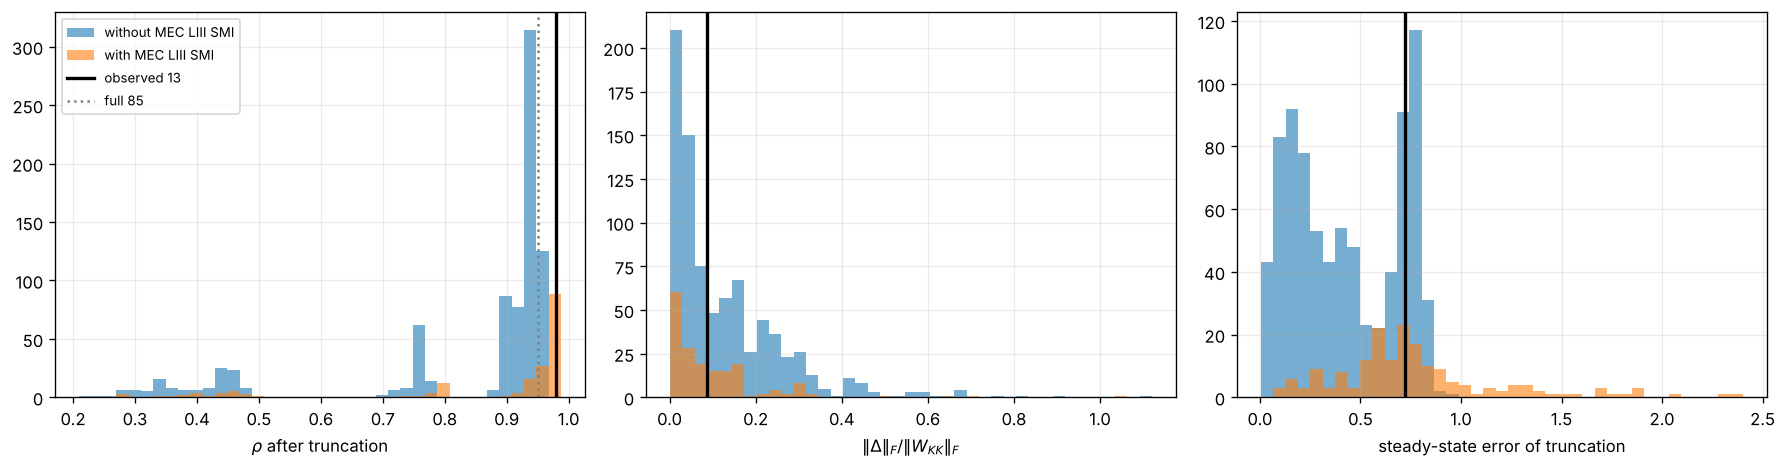

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c, lab in [(axes[0], "rho_truncated", r"$\rho$ after truncation"),
                   (axes[1], "kron_correction_rel", r"$\|\Delta\|_F/\|W_{KK}\|_F$"),
                   (axes[2], "ss_err_truncation", "steady-state error of truncation")]:
    bins = np.linspace(null[c].min(), null[c].max(), 40)
    ax.hist(null.loc[~null.contains_MEC_LIII_SMI, c], bins=bins, alpha=0.6, label="without MEC LIII SMI")
    ax.hist(null.loc[null.contains_MEC_LIII_SMI, c], bins=bins, alpha=0.6, label="with MEC LIII SMI")
    ax.axvline(obs[c], color="k", lw=2, label="observed 13")
    ax.set_xlabel(lab)
axes[0].axvline(0.95, color="gray", ls=":", label="full 85")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "null_ensemble.png", bbox_inches="tight")
plt.show()

## 9. Can the missing types be recovered without their parameters?

This is what transfers to the 122. For the 37 types outside the 85, Hippocampome gives
potential connectivity and E/I class, but not the full $m_{ij}$. Pretend the 13 are in the same
position. Keep their **topology** and **Dale sign**, throw away their weights, impute, and then
Kron-reduce:

* `topology_blockmedian`: $|w|$ = median of known edges in the same E/I block.
* `topology_q_kappa`: use $W[\text{post},\text{pre}] = \kappa_\text{post}\,B\,q_\text{pre}$. Impute only the
  base synaptic term $B$ by block median, and take census $q$ and gain $\kappa$ as known.

Scored on the observed 13 and across the whole null, to check that the ranking of methods is
not specific to one set.

In [14]:
imp_rows = []
for mode in kc.IMPUTATIONS:
    Wr = kc.reduced_operator(P, R, mode)
    imp_rows.append({"method": mode,
                     "steady_state_err": kc.rel_err(kc.transfer(Wr), G_ref),
                     "rho": float(np.max(np.abs(np.linalg.eigvals(Wr)))),
                     "peak_amplification": kc.peak_amplification(Wr)[0],
                     "E_to_I_over_I_to_E": kc.operator_summary(Wr, ei[K], pos[K], mode)["E_to_I_over_I_to_E"]})
imp = pd.DataFrame(imp_rows).set_index("method")
imp["rho_shift_recovered"] = (imp.loc["truncation", "rho"] - imp.rho) / (imp.loc["truncation", "rho"] - imp.loc["oracle", "rho"])
kc.save(imp, "imputation_observed", index=True)

ss = null[[f"ss_err_{m}" for m in kc.IMPUTATIONS[:-1]]]
wins = pd.DataFrame({
    "median_ss_err": ss.median(),
    "share_best": ss.idxmin(axis=1).value_counts(normalize=True).reindex(ss.columns).fillna(0.0),
    "share_better_than_truncation": (ss.lt(ss["ss_err_truncation"], axis=0)).mean(),
})
kc.save(wins, "imputation_null", index=True)
display(imp)
wins

,steady_state_err,rho,peak_amplification,E_to_I_over_I_to_E,rho_shift_recovered
method,,,,,
truncation,0.7203,0.9791,24.99,2308,0
topology_blockmedian,0.6933,0.9787,25,2308,0.0171
topology_q_kappa,0.273,0.9592,24.93,2310,0.7134
oracle,6.671e-15,0.9512,28.39,2497,1


,median_ss_err,share_best,share_better_than_truncation
ss_err_truncation,0.4646,0.023,0
ss_err_topology_blockmedian,0.4604,0.109,0.863
ss_err_topology_q_kappa,0.2736,0.868,0.919


## 10. Summary printout

Numbers for the write-up, collected in one place.

In [15]:
f, t, k = summary.loc["full85"], summary.loc["trunc72"], summary.loc["kron72"]
top = single.iloc[0]
lines = [
    f"Stability margin 1 - rho: full {f.stability_margin:.4f} | truncated {t.stability_margin:.4f} "
    f"({f.stability_margin / t.stability_margin:.2f}x smaller) | Kron {k.stability_margin:.4f}",
    f"Steady-state error of truncation {obs['ss_err_truncation']:.3f}; Kron exact.",
    f"Peak amplification: exact-on-72 {pk['exact_KK'][0]:.2f} | truncation {pk['truncation'][0]:.2f} | static Kron {pk['static_kron'][0]:.2f}",
    f"Henrici: full {f.henrici_relative:.4f} | trunc {t.henrici_relative:.4f} | Kron {k.henrici_relative:.4f}",
    f"E->I / I->E: full {f.E_to_I_over_I_to_E:.0f} | trunc {t.E_to_I_over_I_to_E:.0f} | Kron {k.E_to_I_over_I_to_E:.0f}",
    f"Forward weight fraction: full {f.forward_weight_fraction:.4f} | trunc {t.forward_weight_fraction:.4f} | Kron {k.forward_weight_fraction:.4f}",
    f"Kron Dale: {int(k.dale_wrong_sign_entries)} wrong-sign entries carrying {100 * k.dale_wrong_sign_weight_share:.3f}% of |weight|; "
    f"{int(k.dale_mixed_sign_columns)} of 72 columns mixed-sign",
    f"Largest single effect: {top.neuron_type} (rho if deleted {top.rho_if_deleted:.4f}; correction norm only {top.kron_correction_rel:.4f})",
    f"Null: rho_truncated p = {null_stats.loc[0, 'p_upper']:.3f}, given SMI in set p = {null_stats.loc[0, 'p_upper_given_SMI']:.3f}",
    f"Imputation (rho shift recovered): block-median {imp.loc['topology_blockmedian', 'rho_shift_recovered']:.2f}, "
    f"q+kappa {imp.loc['topology_q_kappa', 'rho_shift_recovered']:.2f}",
]
print("\n".join(lines))

Stability margin 1 - rho: full 0.0500 | truncated 0.0209 (2.40x smaller) | Kron 0.0488
Steady-state error of truncation 0.720; Kron exact.
Peak amplification: exact-on-72 26.58 | truncation 24.97 | static Kron 28.39
Henrici: full 0.9930 | trunc 0.9936 | Kron 0.9943
E->I / I->E: full 912 | trunc 2308 | Kron 2497
Forward weight fraction: full 0.9952 | trunc 0.9959 | Kron 0.9962
Kron Dale: 940 wrong-sign entries carrying 0.034% of |weight|; 57 of 72 columns mixed-sign
Largest single effect: MEC LIII Superficial Multipolar Interneuron (rho if deleted 0.9830; correction norm only 0.0040)
Null: rho_truncated p = 0.033, given SMI in set p = 0.183
Imputation (rho shift recovered): block-median 0.02, q+kappa 0.71


## 11. What this says about applying the method to the full 122

The full interpretation is in `README.md` in this folder. Numbers are from the run above, at
$\rho_\text{full} = 0.95$.

1. **The 85-type operator is a truncation, not a reduction, and truncation moves the
   operating point.** Deleting the 13 cut the stability margin from 0.050 to 0.021 (2.4×).
   At $\rho_\text{full}=0.98$ the truncated 72 is *unstable* while the 85 is stable. Steady-state
   gains are 72% off, although the ranking of responses to DG Granule drive survives
   (Spearman 0.98). The usual renormalisation to $\rho = 0.95$ resets the margin by
   construction, so an independent 72-type analysis could never have seen this. The 85-type
   margin and gains are therefore conditional on the 37 unparameterised types.
2. **Geometry survives; block ratios do not.** Henrici departure (0.993 → 0.994) and forward
   weight fraction (0.995 → 0.996) barely move. Peak amplification is bracketed: truncation
   gives −6% and static Kron +7% around the exact 26.6×. The E→I / I→E ratio is **not** robust
   (912 → 2,308), because the 9 hidden interneurons send 31% of all I→E weight. Under Kron
   reduction, that inhibition does not come back as I→E. It comes back as *negative E→E*:
   49% of the E→E correction weight is negative. Block ratios of a truncated or reduced
   operator reflect which interneurons happen to be parameterised.
3. **One type carries the effect.** MEC LIII Superficial Multipolar Interneuron alone moves
   $\rho$ to 0.983, more than all 13 together, because two hidden excitatory types partly offset
   it. Against E/I-matched random sets, the observed 13 are unusual ($p = 0.033$), but not once
   the set is conditioned on containing that type ($p = 0.18$). What matters is *which* types are
   missing, not how many.
4. **Size is not impact, but alignment can be screened.** CA2 Pyramidal has 21× the correction
   norm of MEC LIII SMI and roughly 1/23 of its spectral effect, with the opposite sign. The
   first-order screen $u^\top\Delta_r v / u^\top v$ matches the exact per-type shifts at $r = 0.99999$.
5. **Census and gain carry the missing information; topology alone does not.** With topology
   and block-median weights, imputation recovers 2% of the stability shift. With topology plus
   $q_i$ and $\kappa_j$ it recovers 71%, and it is the best method in 87% of 1,000 null sets. This
   matches q > κ > wiring in `docs/WEIGHTS_VS_TOPOLOGY.md`.
6. **Use static Kron only for steady state.** It is worse than truncation above
   $\omega \approx 1/\tau$, which is the time scale of the peak at $t \approx 1.2\tau$. For transient
   questions, use the frequency-dependent reduction or keep the hidden types as explicit states.
7. **A Kron-reduced operator fails the orientation oracle in both orientations.** Count purity
   falls to 0.575 / 0.782, while wrong-sign entries carry only 0.034% of |weight|. Any reduced
   matrix needs a weight-share version of `assert_post_pre`.